In [2]:
import pandas as pd
import numpy as np

path = r'C:\Users\13676\Desktop\senna_cohort.csv'
df = pd.read_csv(path, encoding='gb18030',
                 encoding_errors='replace', low_memory=False)

time_cols = ['index_time', 'baseline_k_charttime', 'hypokalemia_time',
             'window_event_time', 'admittime', 'dischtime', 'deathtime',
             'baseline_egfr_charttime']
for c in time_cols:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], dayfirst=True, errors='coerce')

df_main = df.dropna(subset=['senna_exposed', 'hypokalemia_event',
                             'baseline_k', 'age']).copy()
df_main['y'] = df_main['hypokalemia_event'].astype(int)
df_main['senna_exposed'] = df_main['senna_exposed'].astype(int)
df_main['gender_male'] = (df_main['gender'].str.upper().str[0] == 'M').astype(int)

print('df_main 重建完成:', len(df_main), '行')

df_main 重建完成: 41529 行


>>> baseline_k RCS: P for nonlinear = 3.9394e-92


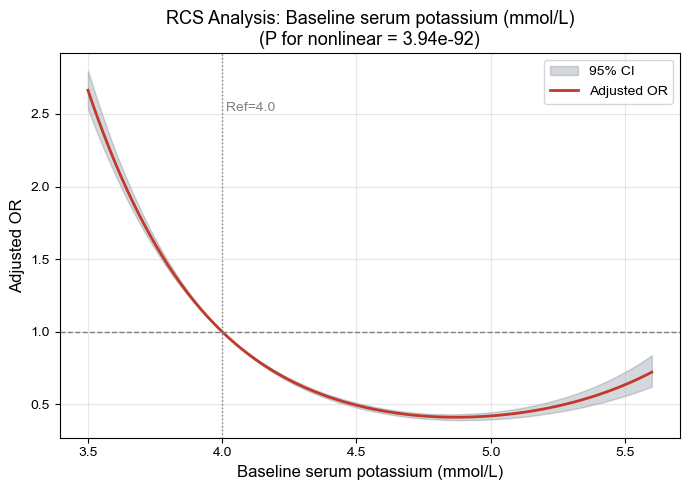

C:\Users\13676\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


>>> drug_count_no_laxatives RCS: P for nonlinear = 1.8289e-03


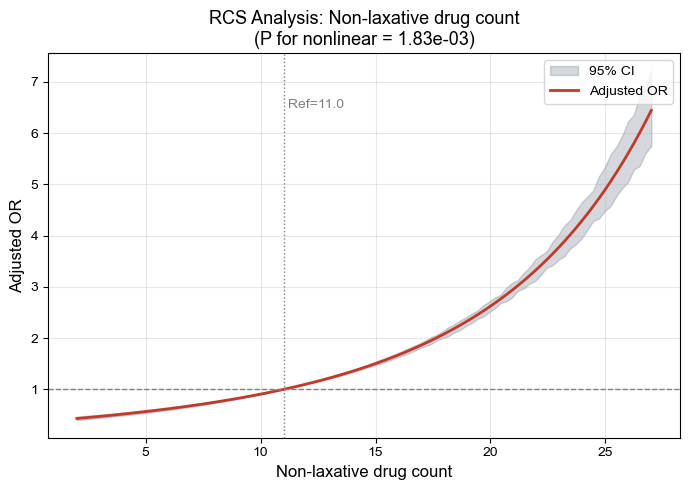

In [4]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import patsy
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.stats import chi2

# ========== 设置字体 ==========
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['axes.unicode_minus'] = False

# 基础清洗（确保无缺失值，防止矩阵对齐报错）
df_rcs = df_main.dropna(subset=['baseline_k', 'drug_count_no_laxatives', 'y']).copy()

# 主模型协变量
COVARS = 'gender_male + C(age_group, Treatment("65-74")) + drug_count_no_laxatives + chf + ckd + dm + diuretic + acei_arb + digoxin + insulin + statin + anticoagulant + lactulose + peg + bisacodyl + ppi + beta2_agonist + corticosteroid'

# ========== 稳健版 RCS 通用函数 ==========
def run_rcs_stable(df, var_name, ref_value, x_label, save_name):
    # 1. 拟合模型（样条 vs 线性）
    formula_spline = f'y ~ cr({var_name}, df=3) + {COVARS}'
    model_spline = smf.logit(formula_spline, data=df).fit(disp=0)
    
    formula_linear = f'y ~ {var_name} + {COVARS}'
    model_linear = smf.logit(formula_linear, data=df).fit(disp=0)
    
    # 2. 计算 P for nonlinear
    lr_stat = 2 * (model_spline.llf - model_linear.llf)
    p_nonlinear = chi2.sf(lr_stat, 2)
    print(f'>>> {var_name} RCS: P for nonlinear = {p_nonlinear:.4e}')
    
    # 3. 生成预测序列
    x_range = np.linspace(df[var_name].quantile(0.01), df[var_name].quantile(0.99), 100)
    
    # 构建预测 DataFrame (复制基础数据，只替换目标变量)
    pred_data = df.iloc[0:len(x_range)].copy()
    pred_data[var_name] = x_range
    pred_ref = pred_data.copy()
    pred_ref[var_name] = ref_value
    
    # 4. 核心修复：用 patsy.build_design_matrices 生成矩阵
    # 这样能完美继承原模型的环境，不会报 NameError
    X_spline = patsy.build_design_matrices([model_spline.model.data.design_info], pred_data, return_type='dataframe')[0]
    X_ref    = patsy.build_design_matrices([model_spline.model.data.design_info], pred_ref, return_type='dataframe')[0]
    
    # 5. 手动矩阵计算 (避开 predict 函数)
    params = model_spline.params
    log_odds_diff = np.dot(X_spline.values, params) - np.dot(X_ref.values, params)
    
    cov_matrix = model_spline.cov_params()
    diff_matrix = X_spline.values - X_ref.values
    se = np.sqrt(np.diag(np.dot(np.dot(diff_matrix, cov_matrix), diff_matrix.T)))
    
    OR = np.exp(log_odds_diff)
    lower_ci = np.exp(log_odds_diff - 1.96 * se)
    upper_ci = np.exp(log_odds_diff + 1.96 * se)
    
    # 6. 画图
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.fill_between(x_range, lower_ci, upper_ci, color='#2C3E50', alpha=0.2, label='95% CI')
    ax.plot(x_range, OR, color='#C0392B', linewidth=2, label='Adjusted OR')
    
    ax.axhline(1, color='gray', linestyle='--', linewidth=1)
    ax.axvline(ref_value, color='gray', linestyle=':', linewidth=1)
    ax.text(ref_value, max(upper_ci)*0.9, f' Ref={ref_value}', color='gray', fontsize=10)
    
    ax.set_xlabel(x_label, fontsize=12)
    ax.set_ylabel('Adjusted OR', fontsize=12)
    ax.set_title(f'RCS Analysis: {x_label}\n(P for nonlinear = {p_nonlinear:.2e})', fontsize=13)
    ax.legend(loc='upper right')
    ax.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(save_name, dpi=300, bbox_inches='tight')
    plt.show()

# ========== 执行 ==========
# 1. 基线血钾
run_rcs_stable(df_rcs, 'baseline_k', 4.0, 'Baseline serum potassium (mmol/L)', 'Figure_RCS_baseline_k.png')

# 2. 非泻药合并用药数
med_drug = df_rcs['drug_count_no_laxatives'].median()
run_rcs_stable(df_rcs, 'drug_count_no_laxatives', med_drug, 'Non-laxative drug count', 'Figure_RCS_drug_count.png')